<a href="https://colab.research.google.com/github/ercanaksakal/turkce-mini-gpt/blob/main/adim2_mini_turkce_gptkatman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adım 2 — Mini Türkçe Dil Modeli (Mini GPT)
Bu defterde sıfırdan, her satırını kendimiz yazdığımız bir **dil modeli** eğiteceğiz.

**Görev:** Model bir metin parçasına bakıp **bir sonraki karakteri** tahmin edecek. ChatGPT de temelde aynı şeyi yapar; sadece karakter yerine kelime parçalarıyla ve milyarlarca parametreyle.

**Plan:**
1. Kurulum ve Drive bağlantısı
2. Türkçe Vikipedi'den ~5 milyon karakterlik veri
3. Metni sayılara çevirme (karakter sözlüğü)
4. **Model A — Bigram:** En basit dil modeli (taban çizgisi)
5. **Model B — Mini GPT:** Kendi Transformer'ımız (self-attention)
6. Eğitim: AdamW + warmup + cosine decay + karma hassasiyet + checkpoint
7. Modelin kendi Türkçe metnini üretmesi

**Başlamadan önce:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU`.

Add `%load_ext cudf.pandas` before importing pandas to speed up operations using GPU

In [45]:
%load_ext cudf.pandas
import pandas as pd
import numpy as np

# Randomly generated dataset of parking violations-
# Define the number of rows
num_rows = 1000000

states = ["NY", "NJ", "CA", "TX"]
violations = ["Double Parking", "Expired Meter", "No Parking",
              "Fire Hydrant", "Bus Stop"]
vehicle_types = ["SUBN", "SDN"]

# Create a date range
start_date = "2022-01-01"
end_date = "2022-12-31"
dates = pd.date_range(start=start_date, end=end_date, freq='D')

# Generate random data
data = {
    "Registration State": np.random.choice(states, size=num_rows),
    "Violation Description": np.random.choice(violations, size=num_rows),
    "Vehicle Body Type": np.random.choice(vehicle_types, size=num_rows),
    "Issue Date": np.random.choice(dates, size=num_rows),
    "Ticket Number": np.random.randint(1000000000, 9999999999, size=num_rows)
}

# Create a DataFrame
df = pd.DataFrame(data)

# Which parking violation is most commonly committed by vehicles from various U.S states?

(df[["Registration State", "Violation Description"]]  # get only these two columns
 .value_counts()  # get the count of offences per state and per type of offence
 .groupby("Registration State")  # group by state
 .head(1)  # get the first row in each group (the type of offence with the largest count)
 .sort_index()  # sort by state name
 .reset_index()
)

The cudf.pandas extension is already loaded. To reload it, use:
  %reload_ext cudf.pandas


,Registration State,Violation Description,count
0,CA,Fire Hydrant,50360
1,NJ,Double Parking,50355
2,NY,Double Parking,50084
3,TX,Fire Hydrant,50283


## 1. Kurulum
Bu hücre hem Colab'da hem de ileride kendi PC'nde çalışacak şekilde yazıldı.

In [46]:
%pip install -q datasets

In [47]:
import os, math, time
from dataclasses import dataclass, asdict
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)
print("Cihaz:", device, "| PyTorch:", torch.__version__)

# Colab'daysak Drive'a, kendi PC'mizdeysek yerel klasöre kaydet
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = "/content/drive/MyDrive/yapay_zeka_projesi"
except ImportError:
    PROJE = "./yapay_zeka_projesi"

VERI_DOSYASI = f"{PROJE}/veri/tr_vikipedi.txt"
CKPT = f"{PROJE}/checkpoints/mini_gpt_tr.pt"
os.makedirs(os.path.dirname(VERI_DOSYASI), exist_ok=True)
os.makedirs(os.path.dirname(CKPT), exist_ok=True)
print("Proje klasörü:", PROJE)

Cihaz: cuda | PyTorch: 2.11.0+cu130
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü: /content/drive/MyDrive/yapay_zeka_projesi


## 2. Veri: Türkçe Vikipedi
İlk çalıştırmada Vikipedi'den makaleleri **akış (streaming)** ile çekiyoruz; tüm Vikipedi'yi indirmiyoruz, sadece ihtiyacımız kadarını alıyoruz.
Metin Drive'a kaydedilir; sonraki çalıştırmalarda doğrudan oradan okunur.

In [48]:
HEDEF_KARAKTER = 5_000_000   # ~5 milyon karakter (yaklaşık 1.500 sayfalık kitap)

if os.path.exists(VERI_DOSYASI):
    with open(VERI_DOSYASI, encoding="utf-8") as f:
        metin = f.read()
    print("Veri Drive'dan okundu.")
else:
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", "20231101.tr", split="train", streaming=True)
    parcalar, toplam = [], 0
    for makale in ds:
        parcalar.append(makale["text"])
        toplam += len(makale["text"])
        if toplam >= HEDEF_KARAKTER:
            break
    metin = "\n\n".join(parcalar)
    with open(VERI_DOSYASI, "w", encoding="utf-8") as f:
        f.write(metin)
    print(f"{len(parcalar)} makale indirildi ve kaydedildi.")

print(f"Toplam karakter: {len(metin):,}")
print("\n--- Örnek ---\n", metin[:500])

Veri Drive'dan okundu.
Toplam karakter: 5,009,681

--- Örnek ---
 Cengiz Han (doğum adıyla Temuçin,  – 18 Ağustos 1227), Moğol İmparatorluğu'nun kurucusu ve ilk Kağanı olan Moğol komutan ve hükümdardır. Hükümdarlığı döneminde gerçekleştirdiği hiçbir savaşı kaybetmeyen Cengiz Han, dünya tarihinin en büyük askeri liderlerinden birisi olarak kabul edilmektedir. 13. yüzyılın başında Orta Asya'daki tüm göçebe bozkır kavimlerini birleştirip bir ulus hâline getirerek Moğol siyasi kimliği çatısı altında toplamıştır. Cengiz Han, hükümdarlığı döneminde, 1206-1227 arasın


## 3. Metni sayılara çevirme (tokenizasyon)
Sinir ağları sadece sayılarla çalışır. En basit yöntem: her karaktere bir numara vermek.
Çok nadir karakterleri (Çince, Arapça, özel semboller) atıyoruz; aksi hâlde model az görülen yüzlerce karakterle boğuşur.

In [49]:
sayac = Counter(metin)
izinli = set(c for c, n in sayac.items() if n >= 50)          # en az 50 kez geçenler
metin = "".join(c for c in metin if c in izinli)

karakterler = sorted(izinli)
V = len(karakterler)                                          # sözlük boyutu
stoi = {c: i for i, c in enumerate(karakterler)}              # karakter -> sayı
itos = {i: c for i, c in enumerate(karakterler)}              # sayı -> karakter
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda l: "".join(itos[i] for i in l)

print("Sözlük boyutu:", V)
print("Karakterler:", "".join(karakterler))
print("\nencode('Merhaba') =", encode("Merhaba"))
print("decode(...)       =", decode(encode("Merhaba")))

Sözlük boyutu: 120
Karakterler: 
 !"$%&'()*+,-./0123456789:;<=>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz| °²ÇÖÜáâäçèéêíîóöûüāćğİıŞş–—‘’“”→

encode('Merhaba') = [44, 64, 77, 67, 60, 61, 60]
decode(...)       = Merhaba


In [50]:
veri = torch.tensor(encode(metin), dtype=torch.long)
n = int(0.9 * len(veri))
egitim_veri, dogrulama_veri = veri[:n], veri[n:]   # %90 eğitim, %10 doğrulama
print(f"Eğitim: {len(egitim_veri):,} | Doğrulama: {len(dogrulama_veri):,} karakter")

Eğitim: 4,506,633 | Doğrulama: 500,738 karakter


### Eğitim örnekleri nasıl oluşuyor?
Metinden rastgele bir pencere alıyoruz. Girdi `x` ve hedef `y` aynı pencere, ama `y` bir karakter kaydırılmış.
Böylece **tek bir pencere, aslında `blok` kadar ayrı tahmin görevi** içeriyor: "M" → "e", "Me" → "r", "Mer" → "h" ...

In [51]:
# ---- Tüm ayarlar burada ----
BLOK = 128          # model en fazla kaç karakter geriye bakabilir (bağlam penceresi)
YIGIN = 64          # her adımda kaç pencere birlikte işlenir (batch)

def yigin_al(bolum):
    kaynak = egitim_veri if bolum == "egitim" else dogrulama_veri
    ix = torch.randint(len(kaynak) - BLOK - 1, (YIGIN,))
    x = torch.stack([kaynak[i:i + BLOK] for i in ix])
    y = torch.stack([kaynak[i + 1:i + BLOK + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = yigin_al("egitim")
print("Girdi :", repr(decode(xb[0, :20].tolist())))
print("Hedef :", repr(decode(yb[0, :20].tolist())))

Girdi : 'ilimin sorgulanmasın'
Hedef : 'limin sorgulanmasına'


## 4. Model A — Bigram (taban çizgisi)
En aptal dil modeli: sadece **son karaktere** bakıp bir sonrakini tahmin eder. Geçmişi hiç hatırlamaz.
Bunu bir ölçü çubuğu olarak kullanacağız: Mini GPT bundan ne kadar iyi olacak?

**Referans:** Rastgele tahmin eden bir modelin hatası `ln(V)` olur. Hatanın bunun altına inmesi = öğrenme.

In [52]:
print(f"Rastgele tahmin hatası: ln({V}) = {math.log(V):.3f}")

class BigramModel(nn.Module):
    def __init__(self, V):
        super().__init__()
        self.tablo = nn.Embedding(V, V)   # her karakter için "sonra ne gelir" puan tablosu

    def forward(self, idx, hedef=None):
        logits = self.tablo(idx)                              # (B, T, V)
        kayip = None
        if hedef is not None:
            kayip = F.cross_entropy(logits.view(-1, logits.size(-1)), hedef.view(-1))
        return logits, kayip

@torch.no_grad()
def kayip_olc(model, tekrar=50):
    model.eval()
    sonuc = {}
    for bolum in ["egitim", "dogrulama"]:
        kayiplar = torch.zeros(tekrar)
        for k in range(tekrar):
            x, y = yigin_al(bolum)
            _, kayip = model(x, y)
            kayiplar[k] = kayip.item()
        sonuc[bolum] = kayiplar.mean().item()
    model.train()
    return sonuc

@torch.no_grad()
def uret(model, baslangic="\n", uzunluk=300, sicaklik=1.0, top_k=None):
    """Modelden metin üret. sicaklik<1: daha temkinli, >1: daha yaratıcı/dağınık"""
    model.eval()
    idx = torch.tensor([encode(baslangic)], dtype=torch.long, device=device)
    for _ in range(uzunluk):
        logits, _ = model(idx[:, -BLOK:])         # sadece son BLOK karaktere bak
        logits = logits[:, -1, :] / sicaklik      # son konumun tahmini
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float("inf")
        olasilik = F.softmax(logits, dim=-1)
        sonraki = torch.multinomial(olasilik, num_samples=1)
        idx = torch.cat([idx, sonraki], dim=1)
    model.train()
    return decode(idx[0].tolist())

Rastgele tahmin hatası: ln(120) = 4.787


In [53]:
bigram = BigramModel(V).to(device)
opt = torch.optim.AdamW(bigram.parameters(), lr=1e-2)

for adim in range(3000):
    x, y = yigin_al("egitim")
    _, kayip = bigram(x, y)
    opt.zero_grad(set_to_none=True)
    kayip.backward()
    opt.step()
    if adim % 1000 == 0 or adim == 2999:
        k = kayip_olc(bigram)
        print(f"Adım {adim:5d} | eğitim: {k['egitim']:.3f} | doğrulama: {k['dogrulama']:.3f}")

BIGRAM_KAYIP = kayip_olc(bigram)["dogrulama"]
print("\n--- Bigram'ın ürettiği metin ---")
print(uret(bigram, "Türkiye", 300))

Adım     0 | eğitim: 5.252 | doğrulama: 5.228
Adım  1000 | eğitim: 2.672 | doğrulama: 2.732
Adım  2000 | eğitim: 2.654 | doğrulama: 2.716
Adım  2999 | eğitim: 2.646 | doğrulama: 2.713

--- Bigram'ın ürettiği metin ---
Türkiyedapecirdusizelabilehi girurı 7

Krgen İteni izaşaze; ema üy, tilildışı ik uğışiçiti adalmu KESerazin kbitıklarılildisirdedimin
Femınlen Muğila or. ticolayusonıre vanri, üzi barcum4231. ka 170 ştıyar iriminmlgak Tün Span 220° azyeriri vamasadiylaşk manekinbedelimaştaye i.
Avevrağlandeminümabiyıştiliç


Bigram metni Türkçe harf dizilimlerine benzer ama anlamsızdır, çünkü sadece bir önceki karaktere bakıyor.
Çözüm: modelin **geçmişin tamamına bakabilmesi** ve hangi kısmın önemli olduğuna kendisi karar vermesi. Bu mekanizmanın adı **dikkat (attention)**.

## 5. Model B — Mini GPT
### Self-attention'ın sezgisi
Cümlenin her karakteri üç vektör üretir:
- **Sorgu (Query):** "Ben neyi arıyorum?"
- **Anahtar (Key):** "Bende ne var?"
- **Değer (Value):** "Seçilirsem ne aktarırım?"

Her karakter kendi sorgusunu geçmişteki tüm anahtarlarla karşılaştırır, en uyumlu olanlara daha çok dikkat eder ve onların değerlerini toplar.
**Maske** sayesinde model geleceğe bakamaz — yoksa sonraki karakteri "kopya çekerek" bilirdi.

**Çok kafalı dikkat:** Aynı işlemi birden fazla "kafa" paralel yapar; biri hece yapısına, biri kelime sınırlarına, biri ek uyumuna odaklanabilir.

### Blok yapısı
`dikkat → ileri beslemeli ağ`, her biri **artık bağlantı (residual)** ve **LayerNorm** ile. Bu blokları üst üste diziyoruz — 1. adımda derinliğin neden işe yaradığını görmüştük.

In [54]:
@dataclass
class Ayar:
    sozluk: int
    blok: int = BLOK
    gomme: int = 256      # her karakteri temsil eden vektörün boyutu
    kafa: int = 4         # dikkat kafası sayısı
    katman: int = 4       # üst üste blok sayısı
    dropout: float = 0.1  # ezberlemeyi önlemek için rastgele nöron kapatma


class OzDikkat(nn.Module):
    """Maskeli çok kafalı self-attention"""
    def __init__(self, a):
        super().__init__()
        assert a.gomme % a.kafa == 0
        self.kafa = a.kafa
        self.qkv = nn.Linear(a.gomme, 3 * a.gomme, bias=False)   # Q, K, V tek seferde
        self.cikis = nn.Linear(a.gomme, a.gomme)
        self.drop = nn.Dropout(a.dropout)
        # Alt üçgen maske: her konum sadece kendisini ve geçmişi görebilir
        self.register_buffer("maske", torch.tril(torch.ones(a.blok, a.blok)).view(1, 1, a.blok, a.blok))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        hs = C // self.kafa
        # (B, T, C) -> (B, kafa, T, hs): her kafa kendi alt uzayında çalışır
        q = q.view(B, T, self.kafa, hs).transpose(1, 2)
        k = k.view(B, T, self.kafa, hs).transpose(1, 2)
        v = v.view(B, T, self.kafa, hs).transpose(1, 2)

        skor = (q @ k.transpose(-2, -1)) / math.sqrt(hs)                # sorgu-anahtar uyumu
        skor = skor.masked_fill(self.maske[:, :, :T, :T] == 0, float("-inf"))  # geleceği gizle
        agirlik = F.softmax(skor, dim=-1)                                # dikkat yüzdeleri
        agirlik = self.drop(agirlik)
        y = agirlik @ v                                                  # değerlerin ağırlıklı toplamı

        y = y.transpose(1, 2).contiguous().view(B, T, C)                 # kafaları birleştir
        return self.drop(self.cikis(y))


class IleriBesleme(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.ag = nn.Sequential(
            nn.Linear(a.gomme, 4 * a.gomme),
            nn.GELU(),
            nn.Linear(4 * a.gomme, a.gomme),
            nn.Dropout(a.dropout),
        )
    def forward(self, x):
        return self.ag(x)


class Blok(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.ln1 = nn.LayerNorm(a.gomme)
        self.dikkat = OzDikkat(a)
        self.ln2 = nn.LayerNorm(a.gomme)
        self.mlp = IleriBesleme(a)
    def forward(self, x):
        x = x + self.dikkat(self.ln1(x))   # artık bağlantı: bilgiyi kaybetmeden ekle
        x = x + self.mlp(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, a):
        super().__init__()
        self.a = a
        self.karakter_gomme = nn.Embedding(a.sozluk, a.gomme)   # "hangi karakter?"
        self.konum_gomme = nn.Embedding(a.blok, a.gomme)        # "kaçıncı sırada?"
        self.drop = nn.Dropout(a.dropout)
        self.bloklar = nn.Sequential(*[Blok(a) for _ in range(a.katman)])
        self.ln_son = nn.LayerNorm(a.gomme)
        self.kafa = nn.Linear(a.gomme, a.sozluk)                # her karakter için puan
        self.apply(self._baslat)

    def _baslat(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, hedef=None):
        B, T = idx.shape
        konum = torch.arange(T, device=idx.device)
        x = self.drop(self.karakter_gomme(idx) + self.konum_gomme(konum))
        x = self.bloklar(x)
        logits = self.kafa(self.ln_son(x))
        kayip = None
        if hedef is not None:
            kayip = F.cross_entropy(logits.view(-1, logits.size(-1)).float(), hedef.view(-1))
        return logits, kayip


ayar = Ayar(sozluk=V)
model = MiniGPT(ayar).to(device)
print(ayar)
print(f"Toplam parametre: {sum(p.numel() for p in model.parameters()):,}")

Ayar(sozluk=120, blok=128, gomme=256, kafa=4, katman=4, dropout=0.1)
Toplam parametre: 3,250,808


## 6. Eğitim
Büyük modellerde kullanılan tekniklerin küçük versiyonları:
- **AdamW:** Adam + ağırlık sönümleme (ezberlemeye karşı)
- **Warmup + cosine decay:** Öğrenme hızı önce yavaşça yükselir, sonra kosinüs eğrisiyle azalır (1. adımdaki `nan` patlamasını hatırla!)
- **Gradyan kırpma:** Ani büyük düzeltmeleri sınırlar
- **Karma hassasiyet (fp16):** GPU'da ~2 kat hız ve yarı bellek
- **Checkpoint + devam:** Colab oturumu koparsa hücreyi tekrar çalıştır, kaldığı yerden devam eder

T4 GPU'da yaklaşık **5–10 dakika** sürer.

In [55]:
ADIM = 5000
ISINMA = 200
MAKS_LR = 1e-3
MIN_LR = 1e-4
OLCUM_ARALIGI = 500

def lr_hesapla(adim):
    if adim < ISINMA:                                   # warmup: doğrusal artış
        return MAKS_LR * (adim + 1) / ISINMA
    oran = min(1.0, (adim - ISINMA) / max(1, ADIM - ISINMA))
    return MIN_LR + 0.5 * (MAKS_LR - MIN_LR) * (1 + math.cos(math.pi * oran))   # cosine decay

opt = torch.optim.AdamW(model.parameters(), lr=MAKS_LR, weight_decay=0.1, betas=(0.9, 0.95))
amp_acik = (device == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=amp_acik)

# ---- Varsa checkpoint'ten devam et ----
baslangic_adim, gecmis = 0, []
if os.path.exists(CKPT):
    k = torch.load(CKPT, map_location=device)
    if k.get("karakterler") == karakterler and k.get("ayar") == asdict(ayar):
        model.load_state_dict(k["model"])
        opt.load_state_dict(k["optimizer"])
        baslangic_adim, gecmis = k["adim"] + 1, k.get("gecmis", [])
        print(f"Checkpoint bulundu, {baslangic_adim}. adımdan devam ediliyor.")
    else:
        print("Checkpoint farklı veri/ayarla kaydedilmiş, sıfırdan başlanıyor.")

def kaydet(adim):
    torch.save({
        "model": model.state_dict(), "optimizer": opt.state_dict(),
        "adim": adim, "ayar": asdict(ayar), "karakterler": karakterler, "gecmis": gecmis,
    }, CKPT)

t0 = time.time()
for adim in range(baslangic_adim, ADIM):
    for g in opt.param_groups:
        g["lr"] = lr_hesapla(adim)

    x, y = yigin_al("egitim")
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=amp_acik):
        _, kayip = model(x, y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(kayip).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # gradyan kırpma
    scaler.step(opt)
    scaler.update()

    if adim % OLCUM_ARALIGI == 0 or adim == ADIM - 1:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=amp_acik):
            k = kayip_olc(model)
        gecmis.append((adim, k["egitim"], k["dogrulama"]))
        print(f"Adım {adim:5d} | lr {lr_hesapla(adim):.2e} | eğitim: {k['egitim']:.3f} | "
              f"doğrulama: {k['dogrulama']:.3f} | {time.time() - t0:.0f} sn")
        kaydet(adim)

print(f"\nBitti. Bigram doğrulama hatası: {BIGRAM_KAYIP:.3f} → Mini GPT: {gecmis[-1][2]:.3f}")

Adım     0 | lr 5.00e-06 | eğitim: 4.847 | doğrulama: 4.836 | 1 sn
Adım   500 | lr 9.91e-04 | eğitim: 1.896 | doğrulama: 1.900 | 18 sn
Adım  1000 | lr 9.40e-04 | eğitim: 1.606 | doğrulama: 1.609 | 35 sn
Adım  1500 | lr 8.47e-04 | eğitim: 1.488 | doğrulama: 1.490 | 52 sn
Adım  2000 | lr 7.22e-04 | eğitim: 1.421 | doğrulama: 1.422 | 69 sn
Adım  2500 | lr 5.79e-04 | eğitim: 1.369 | doğrulama: 1.369 | 87 sn
Adım  3000 | lr 4.34e-04 | eğitim: 1.332 | doğrulama: 1.342 | 104 sn
Adım  3500 | lr 3.00e-04 | eğitim: 1.310 | doğrulama: 1.310 | 120 sn
Adım  4000 | lr 1.93e-04 | eğitim: 1.275 | doğrulama: 1.299 | 137 sn
Adım  4500 | lr 1.24e-04 | eğitim: 1.261 | doğrulama: 1.290 | 154 sn
Adım  4999 | lr 1.00e-04 | eğitim: 1.251 | doğrulama: 1.275 | 171 sn

Bitti. Bigram doğrulama hatası: 2.718 → Mini GPT: 1.275


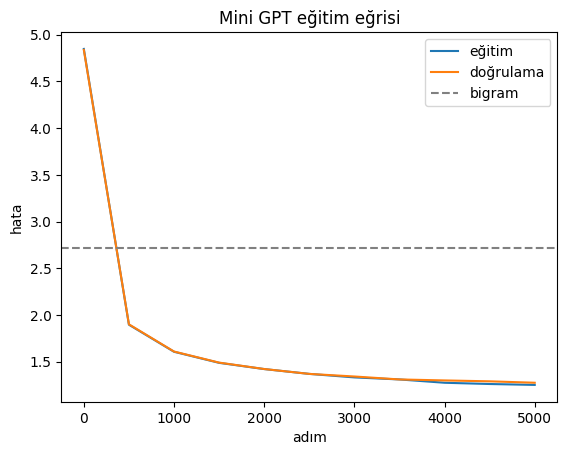

In [56]:
import matplotlib.pyplot as plt
adimlar = [g[0] for g in gecmis]
plt.plot(adimlar, [g[1] for g in gecmis], label="eğitim")
plt.plot(adimlar, [g[2] for g in gecmis], label="doğrulama")
plt.axhline(BIGRAM_KAYIP, color="gray", linestyle="--", label="bigram")
plt.xlabel("adım"); plt.ylabel("hata"); plt.legend(); plt.title("Mini GPT eğitim eğrisi")
plt.show()

## 7. Modelin kendi metni
**Sıcaklık (sicaklik):** Düşükse model en olası karakterleri seçer (tutarlı ama tekdüze), yüksekse riskli seçimler yapar (yaratıcı ama dağınık).
**top_k:** Sadece en olası k karakter arasından seçer; saçma seçimleri engeller.

In [58]:
for baslangic in ["Türkiye", "İstanbul", "Osmanlı İmparatorluğu"]:
    print(f"=== '{baslangic}' ===")
    print(uret(model, baslangic, 400, sicaklik=0.8, top_k=40))
    print()


=== 'Türkiye' ===
Türkiye'ye göre büyük bir dönemde bu sporla açıklamış olan birçok ilişkiyi temsil, yani maçın olmadığı ilgili çalışmalar gibi durumdaki ilk bilgisayar biliminin yanı sıra Fransa, Samsuz Devrimi'nin derini kaybında yer almaktadır. Bilişsel bilgisayar bilimi ve bilimin sonucunda tamamlanması için yapılan kişilere aktarım fiziğinin öğretimini ve kalırsa diğer değişiklikler arası ise bu türlerin da dile geti

=== 'İstanbul' ===
İstanbul Süreninde "Tokat Tek çalışan bir kaynak" olmasından olup oluşmuştur. Bunun zararında yer alan savaşın anlaşılması ise Türkiye'nin en büyük olduğunu belirtmişlerdir. Dünyadaki bütün ilk kanıtlar tarafından oluşur. Doğuşta Sinopolis'in hastalıkları 1980’lerde ise Anadolu ve Linux erkeklerini hareketleri arasında karşılaştırma süreci gerekiyoruz. Türkiye ile Ankara'da başlayan ilk Türkiye'deki Avrup

=== 'Osmanlı İmparatorluğu' ===
Osmanlı İmparatorluğu ve Musullah Sultan Savaşı’nı askerdin tabii sözlerle karşılaştırdı. 1914'te Türkiye'nin İç

## 8. Alıştırmalar
1. **Sıcaklık:** Aynı başlangıçla `sicaklik=0.5`, `1.0` ve `1.5` dene. Hangisi en "Türkçe" görünüyor?
2. **Derinlik:** `Ayar` içinde `katman=6` yap (5. bölümden itibaren tekrar çalıştır). Doğrulama hatası ve süre nasıl değişti? *(Checkpoint ayar farkını algılayıp sıfırdan başlar.)*
3. **Bağlam penceresi:** `BLOK=64` ile dene. Model daha kısa geçmişe baktığında ne kaybediyor?
4. **Aşırı öğrenme gözlemi:** `HEDEF_KARAKTER = 500_000` (10 kat az veri) ile eğit; `VERI_DOSYASI` adını değiştirmeyi unutma. Eğitim ve doğrulama eğrileri arasındaki farka bak.
5. **Bonus — kendi verin:** Kendi metnini (ör. bir yönetmelik metni) `.txt` olarak Drive'a koy ve `VERI_DOSYASI`'nı ona çevir. Az veride ne oluyor?

print(CKPT)
print(os.listdir(os.path.dirname(CKPT)))

## Sonuç tablosu (portföy için doldur)
| Deneme | Parametre | Doğrulama hatası | Süre | Not |
|---|---|---|---|---|
| Bigram |  |  |  |  |
| Mini GPT (4 katman, blok 128) |  |  |  |  |
|  |  |  |  |  |

Add `%load_ext cudf.pandas` before importing pandas to speed up operations using GPU